# 2.0 LabOrch quick start

The 2019-2020 notebook logic now lives in the `laborch` package (one folder up). This notebook shows the same steps as 1.5 and 1.7 using it.

In [11]:
import sys
sys.path.insert(0, '..')   # or: pip install -e ..

import numpy as np
import matplotlib.pyplot as plt
from laborch import Bank, nnls_fit, pinv_fit, dot, INSTRUMENT_NAMES
from laborch.bank import frequencies

## Load the Bank
First call reads 1,515 text files and caches them in `../.cache/fftbank.npz`.

In [12]:
bank = Bank.load()
print(len(bank), 'sounds,', len(bank.instruments), 'instruments')
print([INSTRUMENT_NAMES[i] for i in bank.instruments])

1515 sounds, 33 instruments
['Alto Flute', 'Alto Sax', 'Bass Clarinet', 'Bass Flute', 'Baritone Sax', 'Bassoon', 'Bass Saxophone', 'Bass Trombone', 'Contra Bass Clarinet', 'Contra Bassoon', 'Bb Clarinet', 'Eb Clarinet', 'Crotales', 'Contrabass', 'English Horn', 'Flute', 'French Horn', 'Glockenspiel', 'Marimba', 'Oboe', 'Piccolo', 'Piano', 'Soprano Sax', 'Tuba', 'Tubular Bells', 'Tenor Sax', 'C Trumpet', 'Tenor Trombone', 'Vibraphone', 'Viola', 'Cello', 'Violin', 'Xylophone']


## Target and Ensemble
The 1.7 mock-up example: a trombone F2 imitated by clarinets. The Target is excluded from the Palette.

In [13]:
target_name = 'trb-f2-ord-mf'
target = bank.spectrum(target_name)
palette = bank.select(instruments=['clb', 'bcl'], exclude=[target_name])
len(palette)

62

## Decompose
Pseudo-inverse (RH2009 'SVD') gives negative weights; NNLS does not.

In [14]:
p = pinv_fit(palette, target)
print('negative pinv weights:', (p.weights < 0).sum())

negative pinv weights: 25


In [15]:
fit = nnls_fit(palette, target)
print(fit.summary(6))

nnls: 62 sounds, relative error 0.529
    0.1415  bcl-f2-ord-mf
    0.1171  bcl-f3-ord-mf
    0.0729  clb-f5-ord-mf
    0.0725  clb-g5-ord-mf
    0.0718  clb-f4-ord-mf
    0.0589  clb-c5-ord-mf


In [6]:
print(fit.summary(10))

nnls: 62 sounds, relative error 0.529
    0.1415  bcl-f2-ord-mf
    0.1171  bcl-f3-ord-mf
    0.0729  clb-f5-ord-mf
    0.0725  clb-g5-ord-mf
    0.0718  clb-f4-ord-mf
    0.0589  clb-c5-ord-mf
    0.0492  clb-a4-ord-mf
    0.0483  clb-c4-ord-mf
    0.0398  clb-ds5-ord-mf
    0.0280  clb-e4-ord-mf


## Keep the top N
`top(n)` keeps the weights as they were (the 2020 behaviour); `refit=True` re-solves on the kept sounds.

In [16]:
for n in (1, 3, 8):
    t, r = fit.top(n), fit.top(n, refit=True)
    print(f'N={n}: kept share {fit.kept_fraction(n):.2f}, rel. error {t.relative_error:.3f} -> refit {r.relative_error:.3f}')

N=1: kept share 0.16, rel. error 0.903 -> refit 0.873
N=3: kept share 0.37, rel. error 0.755 -> refit 0.718
N=8: kept share 0.71, rel. error 0.583 -> refit 0.578


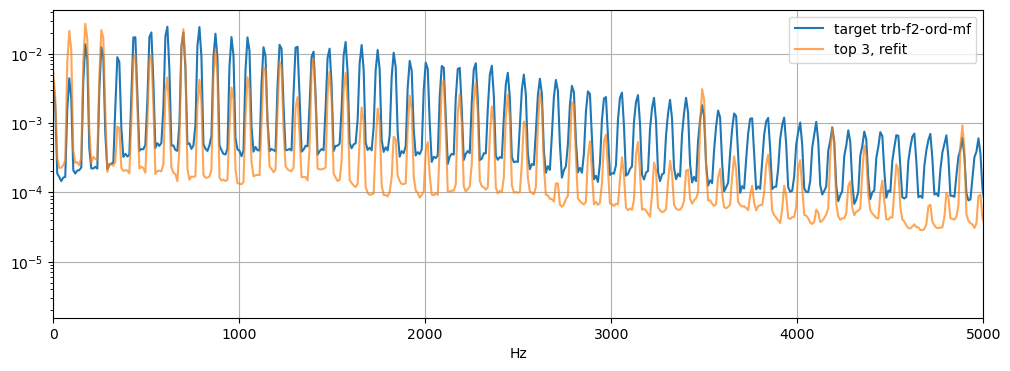

In [17]:
f = frequencies()
r = fit.top(3, refit=True)
plt.figure(figsize=(12, 4))
plt.semilogy(f, target, label='target ' + target_name)
plt.semilogy(f, r.model, label='top 3, refit', alpha=0.7)
plt.xlim(0, 5000); plt.xlabel('Hz'); plt.legend(); plt.grid()

## Listen
Needs pydub + ffmpeg.

In [18]:
from laborch.audio import render_fit
from laborch.spectra import load_segment
mix = render_fit(bank, fit.top(3, refit=True), n=3)
mix

In [10]:
load_segment(bank.sound_path(target_name))